# 16. Tuning XGBoost, and a Fair Comparison with the Other Models

Every model so far used fixed settings. XGBoost in particular ran with 300 trees, learning rate 0.05 and depth 4, chosen as reasonable defaults rather than tuned. This notebook asks:

1. **How much does tuning improve XGBoost?** (16.2–16.3)
2. **Once every model is tuned, is XGBoost still the best, and by how much?** (16.4)
3. **Does the tuned XGBoost do better on the holdout than notebook 14's version?** (16.5)

**Rules, so the comparison stays fair:**

- **All tuning uses the training portion only** (3,539 students; same stratified 80/20 split, `random_state=42`).
- **Stage: After Semester 1**, the stage notebook 14 used to choose the final model. **Score: macro F1.** Balanced class weights are kept for every model.
- The best score from a search is optimistic (it was picked for being high on those folds), so the model comparison uses **nested cross-validation**: the outer 5 folds measure performance, and the search is rerun inside each outer fold using only that fold's training part.
- **Logistic regression and Random Forest get a (smaller) search too**, so tuned XGBoost is compared with tuned versions of the others.
- The holdout is used **once more**, for one comparison planned in advance: tuned vs. default XGBoost. This is its second use (notebook 14 was the first).

**Runtime:** about 10–20 minutes, depending on the computer. Set `QUICK = True` in the setup cell for a much faster, rougher run.

**Reproducibility:** logistic regression and Random Forest give identical numbers on every computer. XGBoost's numbers can shift slightly between XGBoost versions and machines (in the third decimal), so the readings below describe the run saved in this notebook; the conclusions are the same either way.

## 16.0 Setup

In [1]:
import sys
from pathlib import Path

cwd = Path.cwd()
ROOT = next((p for p in (cwd, *cwd.parents) if (p / "src" / "preprocessing.py").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Run from the project root or its notebooks/ directory.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

In [2]:
import time
import warnings
from functools import partial

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from scipy import stats
from scipy.stats import loguniform, randint, uniform
from sklearn.metrics import average_precision_score, f1_score, recall_score
from sklearn.model_selection import (
    RandomizedSearchCV,
    StratifiedKFold,
    train_test_split,
)
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_sample_weight

from src.models import get_logistic_regression, get_random_forest, get_xgboost
from src.plotting import MODEL_ORDER, MODEL_PALETTE, OUTCOME_ORDER
from src.preprocessing import (
    TARGET_COL,
    build_model_pipeline,
    get_feature_availability_sets,
    load_data,
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
STAGE = "After Semester 1"
QUICK = False                      # True = far fewer search iterations, for a fast check
N_ITER_MAIN = 15 if QUICK else 60  # main XGBoost search (gives the final tuned model)
N_ITER_NESTED = {"Logistic Regression": 8 if QUICK else 15,
                 "Random Forest": 5 if QUICK else 15,
                 "XGBoost": 8 if QUICK else 25}
N_BOOT = 2000
FIG_DIR = ROOT / "reports" / "figures"
OUT_DIR = ROOT / "data" / "processed"
FIG_DIR.mkdir(parents=True, exist_ok=True)

df = load_data()
cols = get_feature_availability_sets(df)[STAGE]
y_all = df[TARGET_COL]
train_idx, test_idx = train_test_split(df.index.to_numpy(), test_size=0.20,
                                       random_state=RANDOM_STATE, stratify=y_all)
encoder = LabelEncoder().fit(OUTCOME_ORDER)          # Dropout=0, Enrolled=1, Graduate=2
X_train, X_test = df.loc[train_idx, cols], df.loc[test_idx, cols]
y_train = pd.Series(encoder.transform(y_all.loc[train_idx]), index=train_idx)
y_test = pd.Series(encoder.transform(y_all.loc[test_idx]), index=test_idx)
print(f"Stage: {STAGE} ({len(cols)} predictors) | training {len(train_idx)} | holdout {len(test_idx)}")

Stage: After Semester 1 (30 predictors) | training 3539 | holdout 885


## 16.1 Search spaces

Labels are encoded as integers for every model, so all three use the same scoring and folds. `n_jobs=1` inside each model and parallel folds in the search keeps the run efficient.

| Model | Default (notebooks 03–14) | Settings searched |
|---|---|---|
| Logistic regression | C = 1 | `C` (regularization strength), 0.001–100, log scale |
| Random Forest | 300 trees, no depth limit | `max_depth`, `min_samples_leaf`, `max_features`, class weighting (300 trees) |
| XGBoost | 300 trees, learning rate 0.05, depth 4 | number of trees, learning rate, depth, `min_child_weight`, `subsample`, `colsample_bytree`, `gamma`, `reg_lambda` |

In [3]:
def make_pipe(model_name):
    if model_name == "Logistic Regression":
        model, scale = get_logistic_regression(RANDOM_STATE).set_params(max_iter=3000), True
    elif model_name == "Random Forest":
        model, scale = get_random_forest(RANDOM_STATE).set_params(n_jobs=1), False
    else:
        model, scale = get_xgboost(RANDOM_STATE).set_params(n_jobs=1), False
    return build_model_pipeline(model=model, feature_cols=cols, scale_numeric=scale)


SPACES = {
    "Logistic Regression": {"model__C": loguniform(1e-3, 1e2)},
    "Random Forest": {
        "model__max_depth": [None, 6, 10, 15, 20, 30],
        "model__min_samples_leaf": randint(1, 21),
        "model__max_features": ["sqrt", 0.3, 0.5],
        "model__class_weight": ["balanced", "balanced_subsample"],
    },
    "XGBoost": {
        "model__n_estimators": randint(100, 601),
        "model__learning_rate": loguniform(0.01, 0.3),
        "model__max_depth": randint(2, 8),
        "model__min_child_weight": randint(1, 11),
        "model__subsample": uniform(0.6, 0.4),
        "model__colsample_bytree": uniform(0.5, 0.5),
        "model__gamma": uniform(0, 5),
        "model__reg_lambda": loguniform(0.1, 10),
    },
}


def fit_kwargs(model_name, y):
    # XGBoost gets balanced sample weights; the other two use class_weight inside the model 
    return {"model__sample_weight": compute_sample_weight("balanced", y)} if model_name == "XGBoost" else {}


def search(model_name, X, y, n_iter, cv, seed=RANDOM_STATE):
    rs = RandomizedSearchCV(make_pipe(model_name), SPACES[model_name], n_iter=n_iter, scoring="f1_macro",
                            cv=cv, random_state=seed, n_jobs=-1, refit=True)
    return rs.fit(X, y, **fit_kwargs(model_name, y))

## 16.2 Tune XGBoost on the training portion

60 random combinations, each scored with 5-fold cross-validation on the 3,539 training students. The winner becomes **the tuned XGBoost** used on the holdout in 16.5. Its search score is shown for reference only; 16.4 gives the fair estimate.

In [4]:
inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
t0 = time.time()
xgb_search = search("XGBoost", X_train, y_train, N_ITER_MAIN, inner_cv)
print(f"Search finished in {(time.time() - t0) / 60:.1f} min")

results = pd.DataFrame(xgb_search.cv_results_)
param_cols = [c for c in results if c.startswith("param_model__")]
results = results.rename(columns={c: c.replace("param_model__", "") for c in param_cols})
params = [c.replace("param_model__", "") for c in param_cols]
top = (results.sort_values("mean_test_score", ascending=False)
       [params + ["mean_test_score", "std_test_score"]].head(8).reset_index(drop=True))
display(top.rename(columns={"mean_test_score": "CV macro F1", "std_test_score": "SD"}).round(3))

best_params = {k.replace("model__", ""): v for k, v in xgb_search.best_params_.items()}
default_params = {k: get_xgboost().get_params()[k] for k in best_params}
print("Default vs. tuned settings:")
display(pd.DataFrame({"Default": default_params, "Tuned": best_params}).T)
results[params + ["mean_test_score", "std_test_score"]].to_csv(OUT_DIR / "xgb_tuning_search.csv", index=False)

Search finished in 0.6 min


,colsample_bytree,gamma,learning_rate,max_depth,min_child_weight,n_estimators,reg_lambda,subsample,CV macro F1,SD
0,0.746,0.976,0.117,4,4,134,3.444,0.617,0.707,0.017
1,0.955,1.294,0.095,3,6,153,1.240,0.674,0.702,0.019
2,0.924,1.775,0.259,5,3,466,0.147,0.637,0.702,0.014
3,0.987,1.965,0.208,4,2,376,1.012,0.831,0.701,0.016
4,0.957,2.557,0.055,6,4,420,0.139,0.759,0.700,0.020
5,0.785,2.604,0.263,6,2,466,4.544,0.743,0.700,0.022
6,0.997,2.350,0.026,7,3,479,0.107,0.971,0.699,0.020
7,0.712,2.843,0.071,4,4,565,0.316,0.832,0.698,0.019


Default vs. tuned settings:


,colsample_bytree,gamma,learning_rate,max_depth,min_child_weight,n_estimators,reg_lambda,subsample
Default,NaN,NaN,0.050000,4.0,NaN,300.0,NaN,NaN
Tuned,0.746259,0.976215,0.116721,4.0,4.0,134.0,3.444356,0.617442


## 16.3 Which settings matter?

Each dot is one of the 60 combinations tried. A setting matters if the scores change clearly along its axis; a flat cloud means the setting barely matters within the range searched.

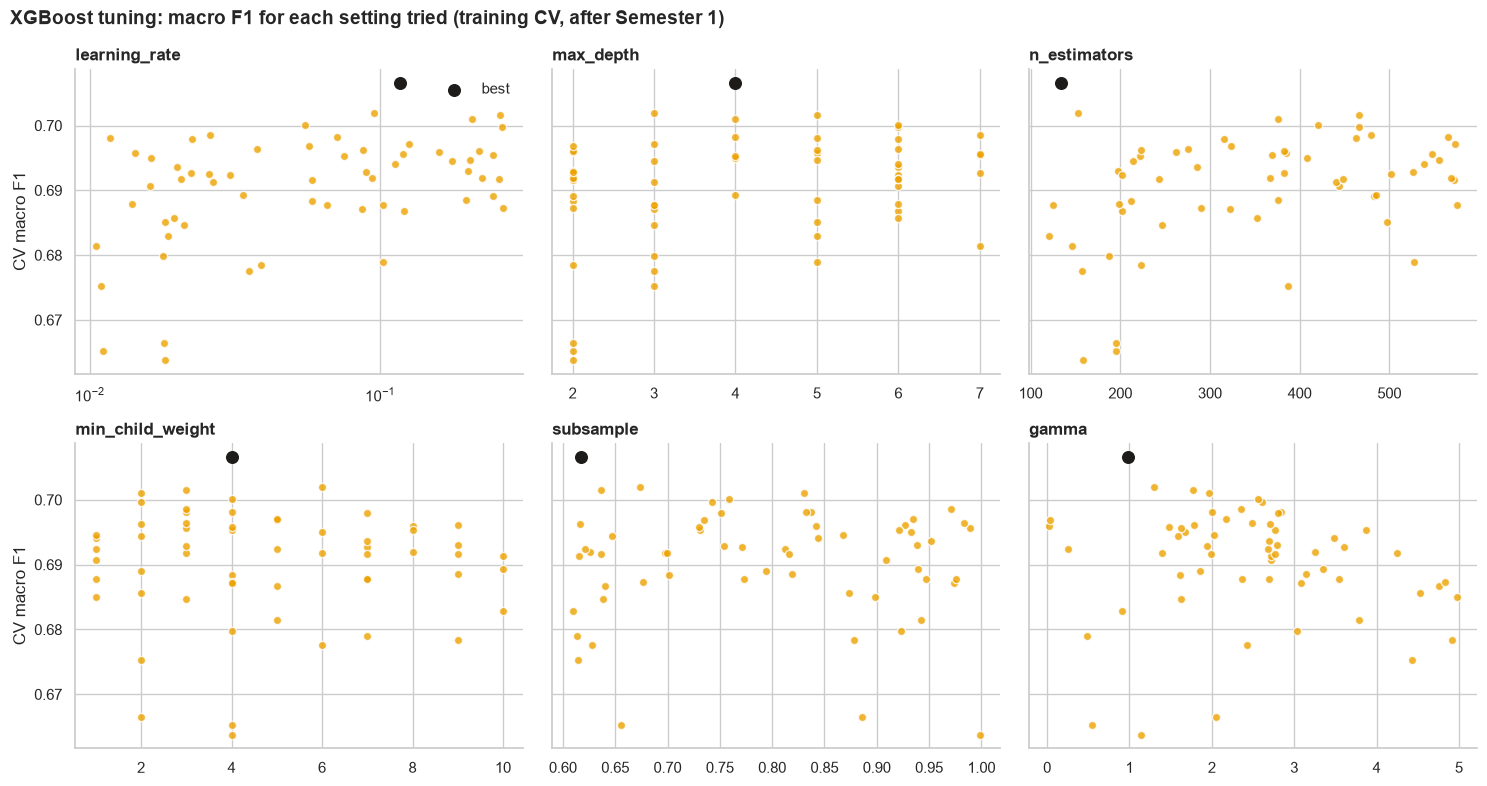

Across all 60 combinations: worst 0.664, median 0.692, best 0.707


In [5]:
show = ["learning_rate", "max_depth", "n_estimators", "min_child_weight", "subsample", "gamma"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharey=True)
for ax, p in zip(axes.flat, show):
    x = results[p].astype(float)
    ax.scatter(x, results["mean_test_score"], color=MODEL_PALETTE["XGBoost"], s=35, alpha=0.8, edgecolor="white")
    best = results.loc[results["mean_test_score"].idxmax()]
    ax.scatter([float(best[p])], [best["mean_test_score"]], color="#1d1c1a", s=70, zorder=5, label="best")
    if p in {"learning_rate"}:
        ax.set_xscale("log")
    ax.set_title(p, loc="left", fontsize=12, fontweight="bold")
axes[0, 0].set_ylabel("CV macro F1")
axes[1, 0].set_ylabel("CV macro F1")
axes[0, 0].legend(frameon=False)
fig.suptitle("XGBoost tuning: macro F1 for each setting tried (training CV, after Semester 1)", x=0.01,
             ha="left", fontsize=14, fontweight="bold")
sns.despine()
plt.tight_layout()
plt.savefig(FIG_DIR / "xgb_tuning_sensitivity.png", dpi=200, bbox_inches="tight")
plt.show()

spread = results["mean_test_score"].agg(["min", "median", "max"])
print(f"Across all {len(results)} combinations: worst {spread['min']:.3f}, median {spread['median']:.3f}, "
      f"best {spread['max']:.3f}")

**Reading 16.3: the search landscape is flat.**

- Across all 60 combinations, macro F1 ranges from 0.664 to 0.707, with a median of 0.692. Most combinations land between 0.685 and 0.700.
- No setting shows a clear trend. The only consistently weak region is a very low learning rate (about 0.01–0.02) combined with few trees, which underfits.
- **The project's default settings were already in the good region.** On these same 5 folds the default XGBoost scores about 0.70 (notebook 14, section 14.1), so the best of 60 tries is less than 0.01 higher. That best score is also optimistic, because it was picked for being high on these folds.
- The winning settings use a faster learning rate (0.12) with fewer trees (134), depth 4, row and column subsampling (0.62 / 0.75) and a bit more regularization (`gamma` ≈ 1, `reg_lambda` ≈ 3.4, `min_child_weight` 4). Section 16.4 checks whether that advantage is real.

## 16.4 Fair comparison: nested cross-validation for every model

For each of the 5 outer folds (on the training portion):

1. Score each model's **default** settings on the outer validation fold.
2. Run that model's search on the outer training part only (3-fold inner CV), refit the best settings, and score the **tuned** version on the same outer validation fold.

So every number below comes from students the tuning never saw, and all six versions are scored on identical folds. Pairs are compared with the corrected resampled t-test used in notebook 07.

In [6]:
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE + 1)
nested_inner = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)


def score_row(y_true, y_pred):
    rec = recall_score(y_true, y_pred, labels=[0, 1, 2], average=None)
    return {"Macro F1": f1_score(y_true, y_pred, average="macro"),
            **{f"{c} recall": r for c, r in zip(OUTCOME_ORDER, rec)}}


nested_rows, chosen = [], []
t0 = time.time()
for k, (fit_pos, val_pos) in enumerate(outer_cv.split(X_train, y_train)):
    X_fit, X_val = X_train.iloc[fit_pos], X_train.iloc[val_pos]
    y_fit, y_val = y_train.iloc[fit_pos], y_train.iloc[val_pos]
    for model_name in MODEL_ORDER:
        default = make_pipe(model_name).fit(X_fit, y_fit, **fit_kwargs(model_name, y_fit))
        nested_rows.append({"Fold": k, "Model": model_name, "Version": "Default",
                            **score_row(y_val, default.predict(X_val))})
        tuned = search(model_name, X_fit, y_fit, N_ITER_NESTED[model_name], nested_inner, seed=RANDOM_STATE + k)
        nested_rows.append({"Fold": k, "Model": model_name, "Version": "Tuned",
                            **score_row(y_val, tuned.predict(X_val))})
        chosen.append({"Fold": k, "Model": model_name,
                       **{p.replace("model__", ""): v for p, v in tuned.best_params_.items()}})
    print(f"outer fold {k + 1}/5 done ({(time.time() - t0) / 60:.1f} min)")

nested = pd.DataFrame(nested_rows)
nested.to_csv(OUT_DIR / "tuning_nested_cv.csv", index=False)
print("Settings chosen inside each outer fold:")
display(pd.DataFrame(chosen).set_index(["Model", "Fold"]).round(3))

outer fold 1/5 done (0.3 min)
outer fold 2/5 done (0.5 min)
outer fold 3/5 done (0.8 min)
outer fold 4/5 done (1.0 min)
outer fold 5/5 done (1.2 min)
Settings chosen inside each outer fold:


,,C,class_weight,max_depth,max_features,min_samples_leaf,colsample_bytree,gamma,learning_rate,min_child_weight,n_estimators,reg_lambda,subsample
Model,Fold,,,,,,,,,,,,
Logistic Regression,0,0.075,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Random Forest,0,NaN,balanced_subsample,15.0,0.5,7.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
XGBoost,0,NaN,NaN,7.0,NaN,NaN,0.655,1.626,0.120,3.0,548.0,0.583,0.989
Logistic Regression,1,0.094,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Random Forest,1,NaN,balanced,NaN,0.3,3.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
XGBoost,1,NaN,NaN,4.0,NaN,NaN,0.646,0.319,0.069,2.0,191.0,5.500,0.953
Logistic Regression,2,0.111,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Random Forest,2,NaN,balanced,10.0,sqrt,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
XGBoost,2,NaN,NaN,4.0,NaN,NaN,0.555,0.261,0.093,10.0,131.0,9.168,0.841


In [7]:
metrics = ["Macro F1"] + [f"{c} recall" for c in OUTCOME_ORDER]
summary = nested.groupby(["Model", "Version"])[metrics].agg(["mean", "std"])
summary.columns = [f"{m} ({s})" for m, s in summary.columns]
summary = summary.reindex(pd.MultiIndex.from_product([MODEL_ORDER, ["Default", "Tuned"]]))
display(summary.round(3))


def corrected_t_p(diff, k_folds=5):
    k = len(diff)
    var = np.var(diff, ddof=1) * (1 / k + 1 / (k_folds - 1))
    return np.nan if var == 0 else 2 * stats.t.sf(abs(np.mean(diff) / np.sqrt(var)), k - 1)


def fold_scores(model, version, metric="Macro F1"):
    return nested[(nested["Model"] == model) & (nested["Version"] == version)].sort_values("Fold")[metric].to_numpy()


pairs = [(("XGBoost", "Tuned"), ("XGBoost", "Default")),
         (("Logistic Regression", "Tuned"), ("Logistic Regression", "Default")),
         (("Random Forest", "Tuned"), ("Random Forest", "Default")),
         (("XGBoost", "Tuned"), ("Logistic Regression", "Tuned")),
         (("XGBoost", "Tuned"), ("Random Forest", "Tuned"))]
pair_rows = []
for a, b in pairs:
    diff = fold_scores(*a) - fold_scores(*b)
    pair_rows.append({"Comparison": f"{a[1]} {a[0]} vs. {b[1]} {b[0]}", "Δ macro F1": diff.mean(),
                      "Folds A better": f"{int((diff > 0).sum())}/{len(diff)}", "Corrected p": corrected_t_p(diff)})
pair_table = pd.DataFrame(pair_rows)
display(pair_table.round(4))

Macro F1 (mean)  Macro F1 (std)  \
Logistic Regression Default            0.681           0.024   
                    Tuned              0.681           0.034   
Random Forest       Default            0.687           0.011   
                    Tuned              0.681           0.013   
XGBoost             Default            0.699           0.024   
                    Tuned              0.693           0.023   

                             Dropout recall (mean)  Dropout recall (std)  \
Logistic Regression Default                  0.711                 0.025   
                    Tuned                    0.707                 0.026   
Random Forest       Default                  0.750                 0.012   
                    Tuned                    0.714                 0.020   
XGBoost             Default                  0.709                 0.021   
                    Tuned                    0.703                 0.015   

                             Enrolled recall (mean)  Enrolled recall (std)  \
Logistic Regression Default                   0.564                  0.048   
                    Tuned                     0.567                  0.066   
Random Forest       Default                   0.424                  0.035   
                    Tuned                     0.506                  0.043   
XGBoost             Default                   0.592                  0.055   
                    Tuned                     0.597                  0.056   

                             Graduate recall (mean)  Graduate recall (std)  
Logistic Regression Default                   0.789                  0.024  
                    Tuned                     0.789                  0.032  
Random Forest       Default                   0.868                  0.017  
                    Tuned                     0.825                  0.024  
XGBoost             Default                   0.812                  0.031  
                    Tuned                     0.800                  0.020

,Comparison,Δ macro F1,Folds A better,Corrected p
0,Tuned XGBoost vs. Default XGBoost,-0.0060,1/5,0.5651
1,Tuned Logistic Regression vs. Default Logistic...,-0.0001,2/5,0.9888
2,Tuned Random Forest vs. Default Random Forest,-0.0055,1/5,0.3664
3,Tuned XGBoost vs. Tuned Logistic Regression,0.0113,4/5,0.4319
4,Tuned XGBoost vs. Tuned Random Forest,0.0113,4/5,0.3611


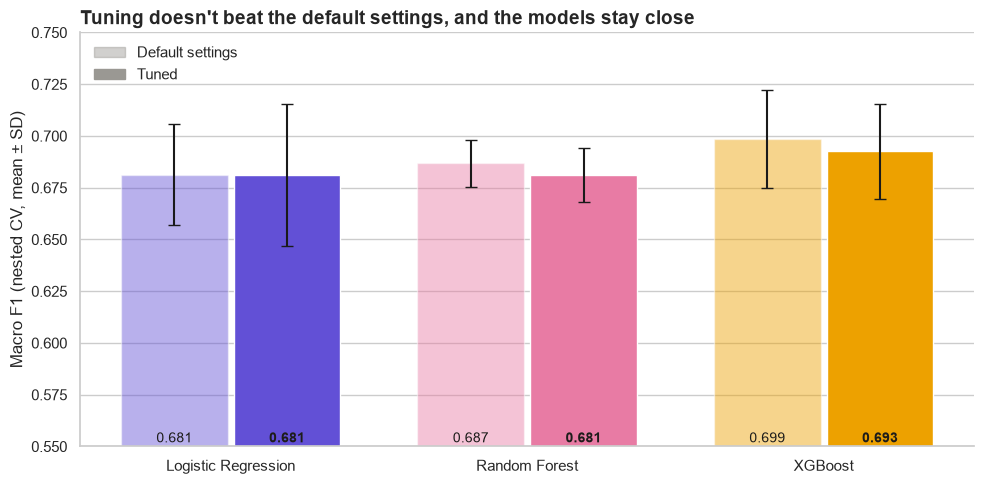

In [8]:
plot_df = nested.groupby(["Model", "Version"])["Macro F1"].agg(["mean", "std"]).reset_index()
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(MODEL_ORDER))
for i, version in enumerate(["Default", "Tuned"]):
    sub = plot_df[plot_df["Version"] == version].set_index("Model").reindex(MODEL_ORDER)
    colors = [MODEL_PALETTE[m] for m in MODEL_ORDER]
    bars = ax.bar(x + (i - 0.5) * 0.38, sub["mean"], 0.36, yerr=sub["std"], capsize=4, color=colors,
                  alpha=0.45 if version == "Default" else 1.0, edgecolor="white")
    for b, v in zip(bars, sub["mean"]):
        ax.text(b.get_x() + b.get_width() / 2, 0.552, f"{v:.3f}", ha="center", fontsize=10,
                color="#1d1c1a", fontweight="bold" if version == "Tuned" else "normal")
ax.set_xticks(x, MODEL_ORDER)
ax.set_ylim(0.55, 0.75)
ax.set_ylabel("Macro F1 (nested CV, mean ± SD)")
handles = [plt.Rectangle((0, 0), 1, 1, color="#9a9893", alpha=0.45), plt.Rectangle((0, 0), 1, 1, color="#9a9893")]
ax.legend(handles, ["Default settings", "Tuned"], frameon=False, loc="upper left")
ax.set_title("Tuning doesn't beat the default settings, and the models stay close", loc="left", fontsize=14,
             fontweight="bold")
ax.grid(axis="x", visible=False)
sns.despine()
plt.tight_layout()
plt.savefig(FIG_DIR / "tuning_nested_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

**Reading 16.4: once measured fairly, tuning doesn't improve any model.**

| Model | Default | Tuned | Change | Corrected p |
|---|---|---|---|---|
| Logistic Regression | 0.681 | 0.681 | −0.000 | 0.99 |
| Random Forest | 0.687 | 0.681 | −0.006 | 0.37 |
| **XGBoost** | **0.699** | **0.693** | −0.006 | 0.57 |

- **Why can tuning score lower?** Each search picks the settings that look best on its own inner folds, partly by chance. When the landscape is flat (16.3), that choice doesn't carry over to new students. Tuned XGBoost beat the default in only 1 of the 5 outer folds, and the folds chose very different settings (depth 3 to 7, learning rate about 0.01 to 0.16, 131 to 548 trees), another sign that there's no clearly better region to find.
- **Tuning moves errors between classes:** tuned Random Forest catches more Enrolled students (42% → 51%) and fewer graduates (87% → 83%). It's more balanced, but macro F1 doesn't change.
- **XGBoost is still the top model** after every model is tuned (+0.011 over both tuned logistic regression and tuned Random Forest), but the gap is not significant (p = 0.43 and 0.36), the same conclusion as notebook 07.

## 16.5 Tuned vs. default XGBoost on the holdout

The tuned XGBoost from 16.2 (refit on all training students) and the default XGBoost (same as notebook 14) are scored on the 885 holdout students. The confidence interval for the **difference** comes from a paired bootstrap: both models are scored on the same resampled students each time.

In [9]:
tuned_final = xgb_search.best_estimator_
default_final = make_pipe("XGBoost").fit(X_train, y_train, **fit_kwargs("XGBoost", y_train))
pred_tuned, pred_default = tuned_final.predict(X_test), default_final.predict(X_test)
yt = y_test.to_numpy()

METRICS = {"Macro F1": partial(f1_score, average="macro"),
           **{f"{c} recall": partial(recall_score, labels=[i], average="macro") for i, c in enumerate(OUTCOME_ORDER)}}
rng = np.random.default_rng(RANDOM_STATE)
boot_idx = [rng.integers(0, len(yt), len(yt)) for _ in range(N_BOOT)]
hold_rows = []
for name, fn in METRICS.items():
    t, dflt = fn(yt, pred_tuned), fn(yt, pred_default)
    diffs = [fn(yt[i], pred_tuned[i]) - fn(yt[i], pred_default[i]) for i in boot_idx]
    lo, hi = np.percentile(diffs, [2.5, 97.5])
    hold_rows.append({"Metric": name, "Default XGBoost (nb 14)": dflt, "Tuned XGBoost": t,
                      "Difference": t - dflt, "95% CI of difference": f"{lo:+.3f} to {hi:+.3f}"})
p_def = default_final.predict_proba(X_test)[:, 0]
p_tun = tuned_final.predict_proba(X_test)[:, 0]
hold_rows.append({"Metric": "Dropout average precision", "Default XGBoost (nb 14)": average_precision_score(yt == 0, p_def),
                  "Tuned XGBoost": average_precision_score(yt == 0, p_tun),
                  "Difference": average_precision_score(yt == 0, p_tun) - average_precision_score(yt == 0, p_def),
                  "95% CI of difference": ""})
holdout = pd.DataFrame(hold_rows)
holdout.to_csv(OUT_DIR / "xgb_tuned_vs_default_holdout.csv", index=False)
display(holdout.round(3))

nb14 = pd.read_csv(OUT_DIR / "final_model_holdout_metrics.csv")
check = nb14[(nb14["Stage"] == STAGE) & (nb14["Metric"] == "Macro F1")]["Holdout"]
if len(check):
    print(f"Check: notebook 14 reported default XGBoost holdout macro F1 = {check.iloc[0]:.3f}")

,Metric,Default XGBoost (nb 14),Tuned XGBoost,Difference,95% CI of difference
0,Macro F1,0.667,0.659,-0.008,-0.029 to +0.010
1,Dropout recall,0.648,0.651,0.004,-0.025 to +0.031
2,Enrolled recall,0.616,0.560,-0.057,-0.117 to +0.000
3,Graduate recall,0.774,0.787,0.014,-0.005 to +0.033
4,Dropout average precision,0.837,0.841,0.004,


Check: notebook 14 reported default XGBoost holdout macro F1 = 0.667


**Reading 16.5: the holdout agrees, tuning doesn't help.**

- Holdout macro F1 is 0.659 for the tuned model vs. 0.667 for the default (difference −0.008, 95% CI −0.029 to +0.010).
- Tuning shifts errors between classes:
  - Enrolled recall falls 5.7 points (CI −11.7 to 0.0, right at the edge of significance).
  - Graduate recall rises 1.4 points and Dropout recall 0.4 points; neither change is significant.
  - Dropout ranking is essentially unchanged (average precision 0.841 vs. 0.837).
- **So the default XGBoost from notebook 14 stays the final classifier.** Its numbers on the slides don't change.

## 16.6 Answer

| Question | Finding |
|---|---|
| How much does tuning improve XGBoost? | **Not measurably.** The best of 60 settings beats the default by less than 0.01 on its own folds, and with nested cross-validation the tuned version scores 0.693 vs. 0.699 for the default (p = 0.57). |
| Once every model is tuned, is XGBoost still best? | Yes, but by about 0.01, which is not significant, the same as before tuning. |
| Does tuned XGBoost do better on the holdout? | No: macro F1 0.659 vs. 0.667. It also catches about 6 points fewer Enrolled students. The default model stays the final classifier. |

**Why this matters:** model choice and tuning each move macro F1 by about 0.01 or less, while adding Semester 1 information moves it by about 0.11. This supports the project's main conjecture: **the limit is the information in the data, not the model.**

**Limitations:**

- The search is randomized, not exhaustive: 60 settings for the main search and 15–25 per model inside each nested fold.
- Tuning was done only after Semester 1 and only for macro F1.
- The holdout was used a second time, for this one planned comparison.
- XGBoost's exact scores vary slightly across library versions and machines (see the note at the top).

Outputs: `data/processed/xgb_tuning_search.csv`, `tuning_nested_cv.csv`, `xgb_tuned_vs_default_holdout.csv`; figures `reports/figures/xgb_tuning_sensitivity.png`, `tuning_nested_comparison.png`.